In [1]:
#!pip install openpyxl

In [2]:
# import common libs
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
# import seaborn as sns


In [3]:
# Import the required classes
from capbet.evaluators.molgenevalsimple import MoleculeSetEvaluatorSimple
from capbet.core.wrappers.molecule import Molecule, MoleculeSet


In [4]:
df_1 = pd.read_csv("../data/interim/molmim/unguided/molmmim_BCS-CN20332_QED_sim03_100p_100m.csv", sep=";")
df_1.sort_values("LogP", ascending=False, inplace=True)

In [5]:
df_1.head()

,smiles,score,LogP,QED
40,CCn1nncc1NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.899226,4.1272,0.899226
44,CCn1nncc1NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.899226,4.1272,0.899226
46,CCn1nncc1NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.899226,4.1272,0.899226
41,CCn1nncc1NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.899226,4.1272,0.899226
48,CCn1nncc1NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.899226,4.1272,0.899226


In [6]:
df_2 = pd.read_csv("../data/interim/molmim/guided/molmmim-Guided_BCS-CN20332_batch2_n100_QED.csv", sep=";")
df_2.sort_values("LogP", ascending=False, inplace=True)
df_2.head()

,valid_smiles,LogP,QED
13,COC(=O)CCNC(=O)c1ccc(-c2ccc(NC(=O)c3ccc(Br)o3)...,4.2543,0.502430
4,COC(=O)CCNC(=O)c1ccc(-c2ccc(C(C)(C)C)cc2)cc1,3.9440,0.839473
15,COC(=O)CCNC(=O)c1ccc(-c2cccc(C(C)(C)C)c2)cc1,3.9440,0.839473
30,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)cc1NC(=O)c1ccc2...,3.8420,0.410694
8,COC(=O)CCNC(=O)c1ccc(-c2cccc3ccccc23)cc1,3.7997,0.722664


In [7]:
df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
df.head()

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN
2,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN
3,BCS-CO63781,['BCS-CO63781'],CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1,120.0,92.0,NaN,NaN,NaN,NaN,1.11,2.72,1710.00,NaN
4,BCS-DC54916,['BCS-DC54916'],C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...,397.0,302.0,NaN,NaN,NaN,NaN,2.85,2.81,10.15,NaN


In [8]:

# Create sample datasets
print("\nCreating sample datasets...")

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles = df_1.smiles 

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles2 = df_2.valid_smiles 

# Reference dataset (for novelty comparison)
reference_smiles = df.std_smiles

# Input dataset (for non-identicality comparison)
input_smiles = [
    "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
]
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"



Creating sample datasets...


In [9]:

# Create MoleculeSet objects
print("Creating MoleculeSet objects...")
print("°°° DF1")
generated_set = MoleculeSet()
generated_set.add_from_smiles_list(generated_smiles)
print("°°° DF2")
generated_set2 = MoleculeSet()
generated_set2.add_from_smiles_list(generated_smiles2)
print("°°° DF-ref = Bayer")
reference_set = MoleculeSet()
reference_set.add_from_smiles_list(reference_smiles)

input_set = MoleculeSet()
input_set.add_from_smiles_list(input_smiles, ["BCS-CN20332"])


Creating MoleculeSet objects...
°°° DF1
°°° DF2
°°° DF-ref = Bayer


In [10]:
len(generated_set)

100

In [11]:

# Evaluate using fingerprint comparison
print("\nEvaluating using fingerprint comparison...")

fp_evaluator = MoleculeSetEvaluatorSimple(
    generated_set=generated_set,
    reference_set=reference_set,
    input_set=input_set,
    comparison_method='fingerprint',
    fingerprint_type='morgan',
    similarity_threshold=1
)

#fp_evaluator.print_report()
#fp_evaluator.plot_metrics(title="Molecule Metrics (Fingerprint Comparison)", save_path="fingerprint_unguided_LogP.png")
#fp_evaluator.add_run("Unguided LogP")



Evaluating using fingerprint comparison...


In [12]:
fp_evaluator.add_run("Unguided QED")

In [13]:
# Now update the evaluator with the second dataset (ref stays the same)
fp_evaluator.generated_set = generated_set2  # Replace with second dataset

# Evaluate and add the first run
#fp_evaluator.print_report()
#fp_evaluator.plot_metrics(title="Molecule Metrics (Unguided LogP)", save_path="fingerprint_unguided_LogP.png")
fp_evaluator.add_run("Guided QED")



Comparing all runs...


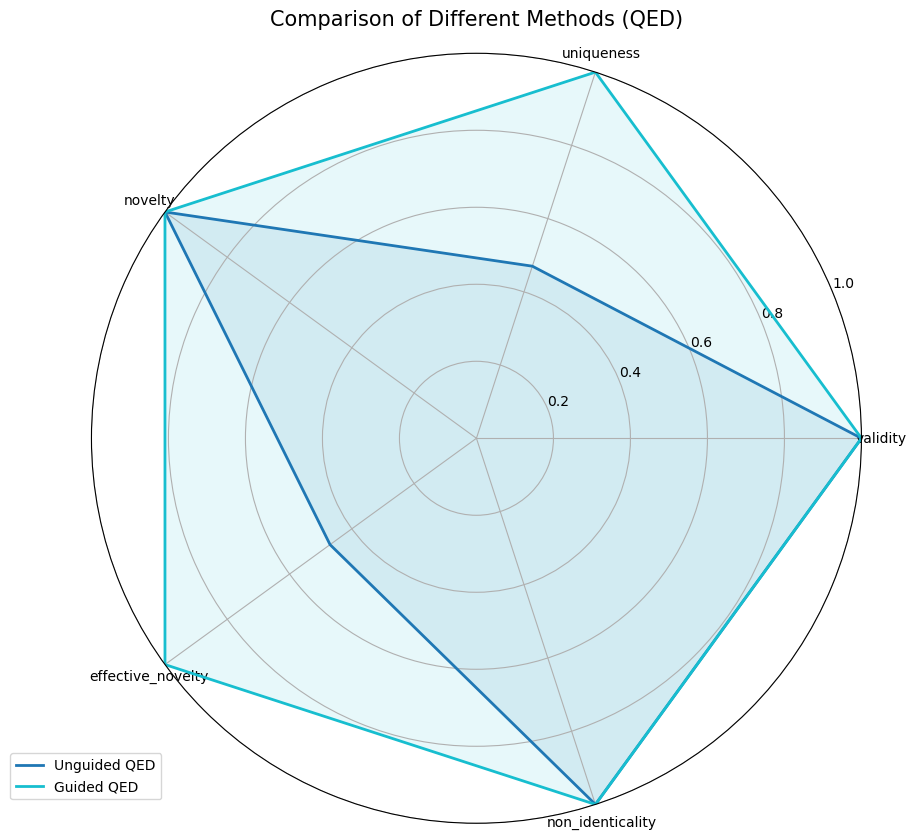

In [14]:

# Now compare all runs
print("\nComparing all runs...")
fp_evaluator.plot_multiple_runs(title="Comparison of Different Methods (QED)", save_path="method_comparison(QED).png")